In [1]:
import pennylane as qml
from pennylane import math as qml_math
from pennylane import numpy as np
from qiskit.quantum_info import Statevector, DensityMatrix
from qiskit.visualization import array_to_latex
from typing import Callable
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from functools import reduce
from scipy.stats import wasserstein_distance

In [2]:
rng = np.random.default_rng(42)

In [3]:
# dev = qml.device("default.qubit")
# dev = qml.device("default.mixed")
### Requires adjusting the error threshold in the following file to allow for probabilities that are close to 1, caused by non-unitary operations:
### ~/research/quantum-dist-rl/.venv/lib/python3.13/site-packages/pennylane/devices/qubit/sampling.py:530
# dev = qml.device("default.qubit", shots=10000)
dev = qml.device("default.qubit", shots=1000)
# dev = qml.device("default.qubit", shots=100)
# dev = qml.device("default.qubit", shots=None)

In [4]:
def is_unitary(m: np.ndarray):
    return np.allclose(np.eye(m.shape[0]), m * m.T.conj())

def is_hermitian(m: np.ndarray):
    return np.allclose(m, m.T.conj())

def is_sorted(x: np.ndarray):
    x = np.array(x)
    return bool(np.all(x[:-1] <= x[1:]))

def softmax(x: np.ndarray):
    y = np.exp(x - np.max(x)) # Stabilize to prevent overflow.
    return y / np.sum(y)

In [5]:
from typing import Any

@qml.qnode(dev)
def circuit(
    wires: list[int],
    funcs: list[Callable[[list[int]], None]] = [],
    func_measure: Callable[[list[int]], Any] = None,
    ):
    if not funcs:
        funcs = [lambda wires: None]
    for func in funcs:
        func(wires)
    if func_measure is not None:
        return func_measure(wires)
    else:
        return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)

In [6]:
def prepare_actions(
    wires_actions: list[int],
    action_probs_vec: np.ndarray, # shape (n_actions,),
    normalize: bool = False,
    ):
    n_actions = action_probs_vec.shape[0]
    
    d_actions = int(np.log2(n_actions))
    # print(f"{d_actions=}")
    if n_actions != 2**d_actions:
        raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(np.sqrt(action_probs_vec), wires=wires_actions, normalize=normalize) # Must normalize since inputs are probability vectors.


def prepare_returns(
    wires_actions: list[int],
    wires_returns: list[int],
    returns_probs_matrix: np.ndarray, # shape (n_actions, n_returns)
    normalize: bool = False,
    ):
    n_actions, n_returns = returns_probs_matrix.shape
    
    d_returns = int(np.log2(n_returns))
    # print(f"{d_returns=}")
    if n_returns != 2**d_returns:
        raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(np.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=normalize) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_actions)


def prepare_action_returns(
    wires: list[int], 
    action_probs_vec: np.ndarray, # shape (n_actions,),
    returns_probs_matrix: np.ndarray, # shape (n_actions, n_returns)
    normalize: bool = False,
    ):
    # print(f"{action_probs_vec.shape=}")
    # print(f"{returns_probs_matrix.shape=}")
    n_actions = action_probs_vec.shape[0]
    n_returns = returns_probs_matrix.shape[1]
    
    # Get number of qubits needed for actions and returns.
    # (for now) The number of actions and returns must be powers of 2 for this to work properly.
    d_actions = int(np.log2(n_actions))
    # print(f"{d_actions=}")
    if n_actions != 2**d_actions:
        raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    d_returns = int(np.log2(n_returns))
    # print(f"{d_returns=}")
    if n_returns != 2**d_returns:
        raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Partition wires into action and return wires.
    # Wire order is: [action wires, return wires]
    if len(wires) != d_actions + d_returns:
        raise ValueError(f"wires must have length {d_actions + d_returns}, got {len(wires)}.")
    wires_action = wires[:d_actions]
    wires_returns = wires[d_actions:]
    # print(f"{wires_action=}, {wires_returns=}")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(np.sqrt(action_probs_vec), wires=wires_action, normalize=normalize) # Must normalize since inputs are probability vectors.
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(np.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=normalize) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_action)

In [7]:
n_actions = 4 # 4, 16
n_returns = 8 # 8, 64
d_actions = int(np.log2(n_actions))
d_returns = int(np.log2(n_returns))

In [8]:
returns_probs_matrix = np.abs(rng.normal(0, 1, size=(n_actions, n_returns)))
returns_probs_matrix = returns_probs_matrix / np.sum(returns_probs_matrix, axis=1, keepdims=True)  # Normalize to make it a probability vector (sums to 1).

# returns_probs_matrix[[0,3]] = returns_probs_matrix[[3,0]] # Swap some rows.
# returns_probs_matrix[[1,3]] = returns_probs_matrix[[1,3]] # Swap some rows.

In [9]:
returns_probs_matrix

tensor([[0.04525715, 0.15446039, 0.11145842, 0.13969444, 0.28977141,
         0.19340215, 0.0189871 , 0.04696894],
        [0.00332887, 0.16901636, 0.17423797, 0.15410644, 0.01308288,
         0.22334395, 0.09262914, 0.1702544 ],
        [0.08196516, 0.21313843, 0.19526011, 0.01109743, 0.04109082,
         0.15135561, 0.27174395, 0.03434849],
        [0.08448562, 0.06945667, 0.10499545, 0.0720821 , 0.08140954,
         0.08497739, 0.42242979, 0.08016343]], requires_grad=True)

In [10]:
# returns_atoms_values_original = softmax(np.array([1.]*n_returns)) # Equal superposition.
# returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns/16) # Monotonically increasing, but very shallow.
returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns) # Monotonically increasing, but similar values.
# returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/2.) # Slightly steeper than previous.
# returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns*4) # More steep than previous.
# returns_atoms_values_original = softmax(np.array([float(i)+1 for i in range(n_returns)])/n_returns*8) # Even more steep than previous.
########
returns_atoms_values_original = returns_atoms_values_original[::-1] # Monotonically decreasing
########
returns_atoms_values_original = returns_atoms_values_original * (n_returns / n_actions)
#########
# np.random.shuffle(returns_atoms_values_original) # Shuffle the return atoms, so that they are not monotonically increasing or decreasing.
#########
returns_atoms_values = returns_atoms_values_original.copy()

# returns_atoms_values = returns_atoms_values_original.copy() # DOES NOT WORK. Must at least have square-root term.
# returns_atoms_values = np.sqrt(returns_atoms_values) # This is minimal working representation. Must at least have square-root of probability distribution. Causes L2-norm of diagonal unitary to be 1.
returns_atoms_values = np.sqrt(returns_atoms_values * n_actions) # values - epsilon (epsilon is zero).
# returns_atoms_values = np.sqrt(returns_atoms_values * n_actions) - 0.0196 # values - epsilon.
# returns_atoms_values = np.sqrt(returns_atoms_values * n_actions) - 0.1 # values - epsilon.
# returns_atoms_values = np.sqrt(returns_atoms_values * n_actions) - 0.001 # values - epsilon.
# returns_atoms_values = np.sqrt(returns_atoms_values*n_actions) # causes a 1:1 match with computing weighted action distribution via expected return.
# returns_atoms_values = np.sqrt(returns_atoms_values*(n_actions*n_returns)/(d_actions*d_returns)*2)
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions # causes L2-norm of circuit probs to be close to 1.
# returns_atoms_values = np.sqrt(returns_atoms_values*n_returns/n_actions)
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions/n_returns
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_returns/n_actions
# returns_atoms_values = np.sqrt(returns_atoms_values)*n_actions/n_returns
# returns_atoms_values = 1j*np.sqrt(returns_atoms_values)*n_returns/n_actions
# returns_atoms_values = 1j*np.sqrt(returns_atoms_values)
# returns_atoms_values = returns_atoms_values + 1j*np.sqrt(1 - returns_atoms_values**2.) # Convert to complex such that the norm of each element is 1. This will cause the diagonal matrix to be unitary.
# returns_atoms_values = np.sqrt(1 - returns_atoms_values**2.) + 1j*returns_atoms_values # Convert to complex such that the norm of each element is 1. This will cause the diagonal matrix to be unitary.
# returns_atoms_values = np.exp(2*np.pi*1j*returns_atoms_values)
# returns_atoms_values = returns_atoms_values / np.linalg.norm(returns_atoms_values)
# returns_atoms_values = np.exp(1j*returns_atoms_values)

##################
# returns_atoms_values = returns_atoms_values/n_actions
##################

# # Swap real/imaginary parts.
# r = returns_atoms_values.real.copy()
# i = returns_atoms_values.imag.copy()
# returns_atoms_values.real = i
# returns_atoms_values.imag = r

U_returns_atoms = np.diag(returns_atoms_values)
##########
# U_returns_atoms = (U_returns_atoms/np.linalg.norm(U_returns_atoms)) * 1/np.sqrt(n_returns)*n_returns

In [35]:
U_returns_atoms

tensor([[1.21946599, 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        ],
        [0.        , 1.14558228, 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        ],
        [0.        , 0.        , 1.07617496, 0.        , 0.        ,
         0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        , 1.01097282, 0.        ,
         0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        , 0.        , 0.94972107,
         0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        , 0.        , 0.        ,
         0.89218038, 0.        , 0.        ],
        [0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.8381259 , 0.        ],
        [0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.78734642]], requires_grad=True)

In [11]:
action_probs_vec_original = [1./n_actions] * n_actions  # Uniform distribution for simplicity
action_probs_vec_original = np.array(action_probs_vec_original) # Convert to numpy array for vectorization.
action_probs_vec = action_probs_vec_original.copy() # Preserve the original.

In [12]:
probs_actions_carryover = None # Reset circuit carryover probabilities between runs.

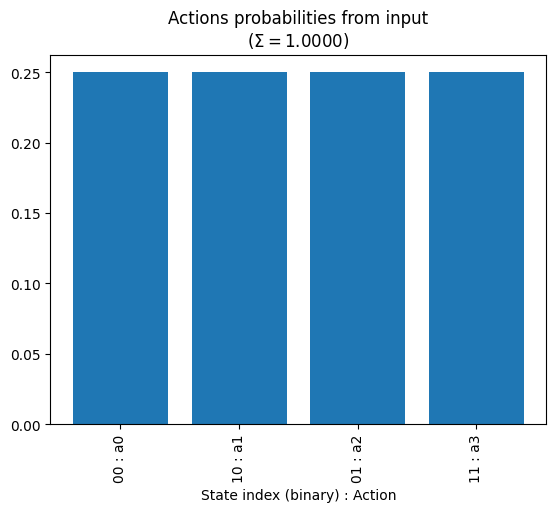

<Figure size 640x480 with 0 Axes>

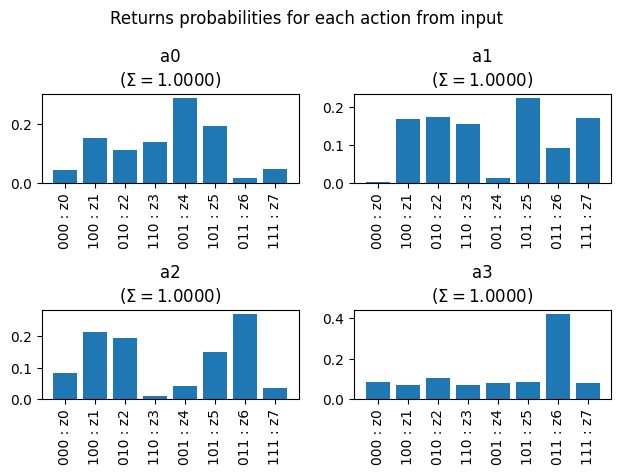

Text(0.5, 0, 'State index (binary) : Action')

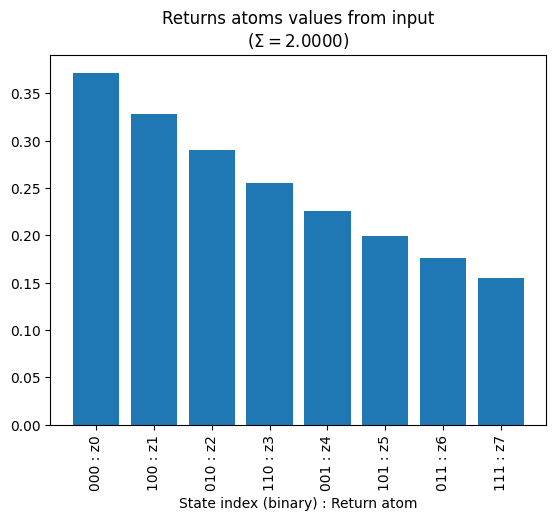

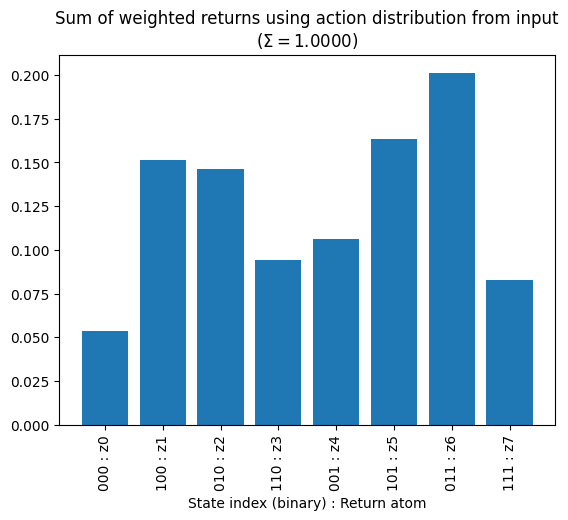

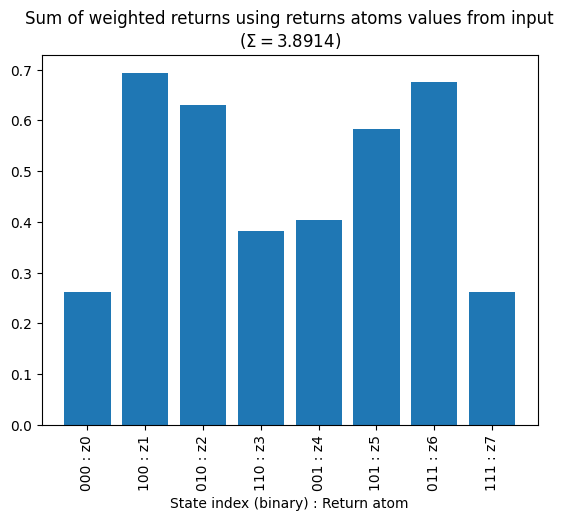

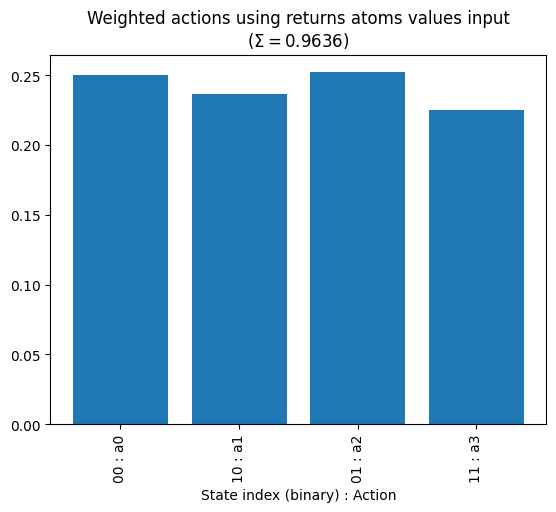

In [13]:
### Plot all inputs for visualization.

plt.figure()
plt.bar(np.arange(n_actions), action_probs_vec)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Actions probabilities from input\n($\\Sigma = {action_probs_vec.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")


plt.figure()
d = int(np.ceil(np.sqrt(n_actions)))
fig, axs = plt.subplots(d, d)
axs = axs.flatten()
for a in range(n_actions):
    axs[a].bar(np.arange(n_returns), returns_probs_matrix[a])
    axs[a].set_xticks(np.arange(n_returns))
    axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
    axs[a].set_title(f"a{a}\n($\\Sigma = {returns_probs_matrix[a].sum():.4f}$)")
plt.suptitle("Returns probabilities for each action from input")
plt.tight_layout()
plt.show()


plt.figure()
plt.bar(np.arange(n_returns), returns_atoms_values_original)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Returns atoms values from input\n($\\Sigma = {returns_atoms_values_original.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

#########

plt.figure()
df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)])
weights = pd.Series(action_probs_vec, index=[f"a{i}" for i in range(n_actions)])
weighted_vec = (df.T * weights).sum(axis=1).to_numpy()
plt.bar(np.arange(n_returns), weighted_vec)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Sum of weighted returns using action distribution from input\n($\\Sigma = {weighted_vec.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")


plt.figure()
M = np.einsum('jj,ij->j', U_returns_atoms, returns_probs_matrix)
plt.bar(np.arange(n_returns), np.abs(M))
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Sum of weighted returns using returns atoms values from input\n($\\Sigma = {np.abs(M).sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

#########

plt.figure()
plt.bar(np.arange(n_actions), returns_probs_matrix @ returns_atoms_values_original)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Weighted actions using returns atoms values input\n($\\Sigma = {(returns_probs_matrix @ returns_atoms_values_original).sum():.4f}$)")
plt.xlabel("State index (binary) : Action")

In [14]:
### Re-run the circuit from here down if you want to re-use the action probabilities from the previous run.
### Otherwise, run from the line above.

probs_actions_carryover = globals().get('probs_actions_carryover', None)
if probs_actions_carryover is not None:
    action_probs_vec = probs_actions_carryover
    print(f'Using action probabilities from previous run: {action_probs_vec}')

In [15]:
# wires = list(range(d_actions + d_returns))
# wires_actions = wires[:d_actions]
# wires_returns = wires[d_actions:]

# # def domeasure():
# #     m = [qml.measure(w) for w in wires_actions]
# #     print(m)

# funcs = [
#     lambda wires: prepare_action_returns(wires, action_probs_vec, returns_probs_matrix, normalize=True), # Prepare the action and return distributions.
#     lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=True),
#     ###########
#     # lambda wires: domeasure(),
#     # lambda wires: qml.measure(wires_actions[0]),
#     # lambda wires: qml.measure(wires_actions[1]),
#     ###########
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
#     # lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False),
# ]
# func_measure = lambda wires: (
#     # qml.state(),
#     # qml.probs(wires=wires),
#     # qml.density_matrix(wires),
#     qml.probs(wires=wires_actions),
#     qml.probs(wires=wires_returns),
#     )
# (
#     # state,
#     # probs,
#     # rho,
#     probs_actions,
#     probs_returns,
#     ) = circuit(wires, funcs=funcs, func_measure=func_measure)

# # # replace state and density matrix rho with dummy values.
# # state = np.array(list(range(2**len(wires))))
# # state = state / np.linalg.norm(state)
# # rho = np.identity(len(state))

# # print(f"{wires_actions=}")
# # print(f"{wires_returns=}")
# # print(f"{probs_actions=}")
# # print(f"{probs_returns=}")
# # print(f"{probs=}")


# # # Split the system density matrix into density matrices for the actions and returns subsystems.
# # rho_actions = qml_math.partial_trace(rho, indices=wires_returns) # This is the reduced density matrix for actions, trace out the returns.
# # rho_returns = qml_math.partial_trace(rho, indices=wires_actions) # This is the reduced density matrix for returns, trace out the actions.

# # display(array_to_latex(action_probs_vec, prefix="\\textrm{Action probabilities vector:~~}"))
# # display(array_to_latex(returns_probs_matrix, prefix="\\textrm{Returns probabilities matrix:~~}"))
# # display(array_to_latex(returns_atoms_values, prefix="\\textrm{Returns atoms values:~~}"))
# # display(array_to_latex(returns_probs_matrix @ returns_atoms_values_original, prefix="\\textrm{Action expected returns (return dist @ return values):~~}"))
# #######
# # display(array_to_latex(state, prefix="\\textrm{State:~~}"))
# # display(Statevector(state).draw(output='latex', prefix="\\textrm{State:~~}"))
# # display(array_to_latex(probs, prefix="\\textrm{Probabilities:~~}"))
# # display(DensityMatrix(rho).draw(output='latex', prefix="\\textrm{Rho:~~}"))
# # display(array_to_latex(rho_actions, prefix="\\textrm{Rho actions:~~}"))
# # display(DensityMatrix(rho_actions).draw(output='latex', prefix="\\textrm{Rho actions:~~}"))
# # display(array_to_latex(rho_returns, prefix="\\textrm{Rho returns:~~}"))
# # display(DensityMatrix(rho_returns).draw(output='latex', prefix="\\textrm{Rho returns:~~}"))

In [16]:
################## Prepare, compute, measure, re-upload, ...
wires = list(range(d_actions + d_returns))
wires_actions = wires[:d_actions]
wires_returns = wires[d_actions:]

funcs = [
    lambda wires: prepare_actions(wires_actions=wires_actions, action_probs_vec=action_probs_vec, normalize=True),
    lambda wires: prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True),
    lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False), # We know it's not unitary, so don't check.
    lambda wires: [qml.measure(wires=w, reset=True) for w in wires_returns],
    # lambda wires: qml.WireCut(wires=wires_returns),
]
N = int(np.sqrt(n_actions * n_returns)) # Run multiple times.
print(f"Re-uploading {N} times")
for _ in range(N):
    funcs.extend([
        ########
        lambda wires: prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True),
        lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False), # We know it's not unitary, so don't check.
        lambda wires: [qml.measure(wires=w, reset=True) for w in wires_returns],
        # lambda wires: qml.WireCut(wires=wires_returns),
        ########
    ])

func_measure = lambda wires: (
    qml.probs(wires=wires_actions),
    qml.probs(wires=wires_returns),
    )
(probs_actions, probs_returns) = circuit(wires, funcs=funcs, func_measure=func_measure)
##################

Re-uploading 5 times
norm=np.float64(0.9999999999999999)
norm_err=np.float64(1.1102230246251565e-16)
probs.shape=(32,), probs=array([8.87806571e-08, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       1.80456708e-05, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       9.65532769e-02, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       9.03428589e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00])
norm=np.float64(1.0000000000000002)
norm_err=np.float64(2.220446049250313e-16)
probs.shape=(32,), probs=array([0.58088522, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.00416978, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,


In [17]:
# #### Cascade of quantum circuits.

# wires = list(range(d_actions + d_returns))
# wires_actions = wires[:d_actions]
# wires_returns = wires[d_actions:]

# N = 1 # Run once.
# # N = int(np.sqrt(n_actions * n_returns)) # Run multiple times.
# print(f"Running {N} times")

# for _ in range(N):
#     funcs = [
#         lambda wires: prepare_action_returns(wires, action_probs_vec, returns_probs_matrix, normalize=True), # Prepare the action and return distributions.
#         lambda wires: qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False), # We know it's not unitary, so don't check.
#     ]
#     func_measure = lambda wires: (
#         qml.probs(wires=wires_actions),
#         qml.probs(wires=wires_returns),
#         )
#     (probs_actions, probs_returns) = circuit(wires, funcs=funcs, func_measure=func_measure)
#     if N > 1:
#         action_probs_vec = probs_actions.copy()

In [18]:
# probs_actions = probs_actions/sum(probs_actions) # Re-normalize action probabilities.

In [19]:
probs_actions # Action probabilities before normalization.

array([0.258, 0.226, 0.313, 0.203])

In [20]:
probs_actions_carryover = probs_actions.copy() # Designate action probabilities to be carried over to the next run.

Matplotlib is building the font cache; this may take a moment.


(<Figure size 3500x600 with 1 Axes>, <Axes: >)

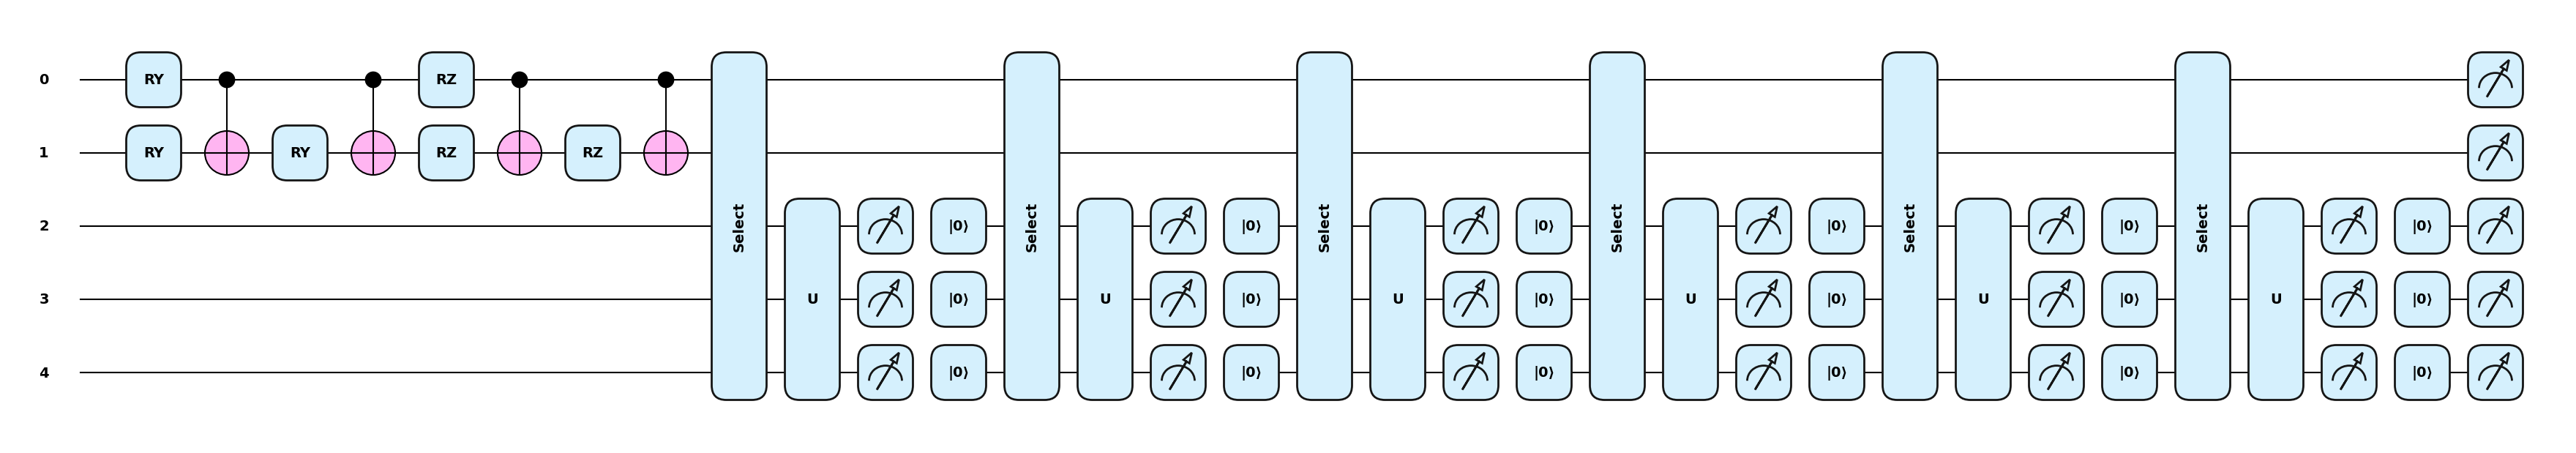

In [32]:
qml.draw_mpl(circuit, wire_order=wires, style='pennylane')(wires, funcs=funcs, func_measure=func_measure)

In [34]:
print(qml.draw(circuit, wire_order=wires)(wires, funcs=funcs, func_measure=func_measure))

0: ──RY(1.57)─╭●───────────╭●──RZ(0.00)─╭●───────────╭●─╭Select──────────────────╭Select─────── ···
1: ──RY(1.57)─╰X──RY(0.00)─╰X──RZ(0.00)─╰X──RZ(0.00)─╰X─├Select──────────────────├Select─────── ···
2: ─────────────────────────────────────────────────────├Select─╭U(M0)──┤↗│  │0⟩─├Select─╭U(M0) ···
3: ─────────────────────────────────────────────────────├Select─├U(M0)──┤↗│  │0⟩─├Select─├U(M0) ···
4: ─────────────────────────────────────────────────────╰Select─╰U(M0)──┤↗│  │0⟩─╰Select─╰U(M0) ···

0: ··· ───────────╭Select──────────────────╭Select──────────────────╭Select───────────────── ···
1: ··· ───────────├Select──────────────────├Select──────────────────├Select───────────────── ···
2: ··· ──┤↗│  │0⟩─├Select─╭U(M0)──┤↗│  │0⟩─├Select─╭U(M0)──┤↗│  │0⟩─├Select─╭U(M0)──┤↗│  │0⟩ ···
3: ··· ──┤↗│  │0⟩─├Select─├U(M0)──┤↗│  │0⟩─├Select─├U(M0)──┤↗│  │0⟩─├Select─├U(M0)──┤↗│  │0⟩ ···
4: ··· ──┤↗│  │0⟩─╰Select─╰U(M0)──┤↗│  │0⟩─╰Select─╰U(M0)──┤↗│  │0⟩─╰Select─╰U(M0)──┤↗│  │0⟩ ···

0: ··· ─╭Sele

Text(0.5, 0, 'State index (binary) : Action')

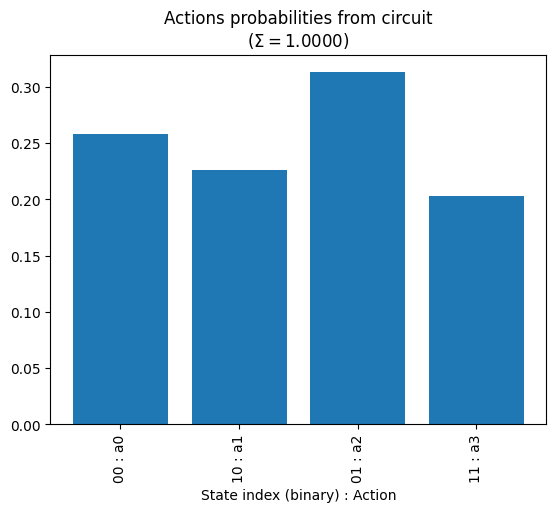

In [22]:
### Probabilities derived from measuring the returns qubits in the circuit.
### NOTE - I've found that the result plotted below will be scaled by a factor of 1/n_actions.

plt.bar(np.arange(n_actions), probs_actions)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Actions probabilities from circuit\n($\\Sigma = {probs_actions.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")

In [23]:
probs_actions.sum()

np.float64(1.0)

In [24]:
probs_actions.sum()**2

np.float64(1.0)

In [25]:
(returns_probs_matrix @ returns_atoms_values_original).sum() / probs_actions.sum()

tensor(0.96356563, requires_grad=True)

In [26]:
from collections import namedtuple
ActionRank = namedtuple("ActionRank", ["action", "rank"])

In [27]:
### Rank actions from high-to-low based on their weighted expected return.

action_rank_manual_compute, _ = zip(*sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1]) # List of action indices where location in list indicates action rank in descending order (high -> low).
action_rank_manual_compute = list(ActionRank(action, rank) for rank,action in enumerate(action_rank_manual_compute)) # [(action_index, rank), ...]
action_rank_manual_compute

[ActionRank(action=2, rank=0),
 ActionRank(action=0, rank=1),
 ActionRank(action=1, rank=2),
 ActionRank(action=3, rank=3)]

In [28]:
### Rank actions from high-to-low based on their circuit probability.

action_rank_circuit_probs, _ = zip(*sorted(list(enumerate(probs_actions)), key=lambda tup: tup[1])[::-1]) # List of action indices where location in list indicates action rank in descending order (high -> low).
action_rank_circuit_probs = list(ActionRank(action, rank) for rank,action in enumerate(action_rank_circuit_probs)) # [(action_index, rank), ...]
action_rank_circuit_probs

[ActionRank(action=2, rank=0),
 ActionRank(action=0, rank=1),
 ActionRank(action=1, rank=2),
 ActionRank(action=3, rank=3)]

In [29]:
### Verify manually computed action rank is the same as the rank estimated by the circuit.

action_rank_manual_compute == action_rank_circuit_probs

True

Text(0.5, 1.0, 'Comparison of action probabilities between circuit and manual computation\n(Action ranking provided above each bar, lower rank number is better)\nRank match = True')

<Figure size 640x480 with 0 Axes>

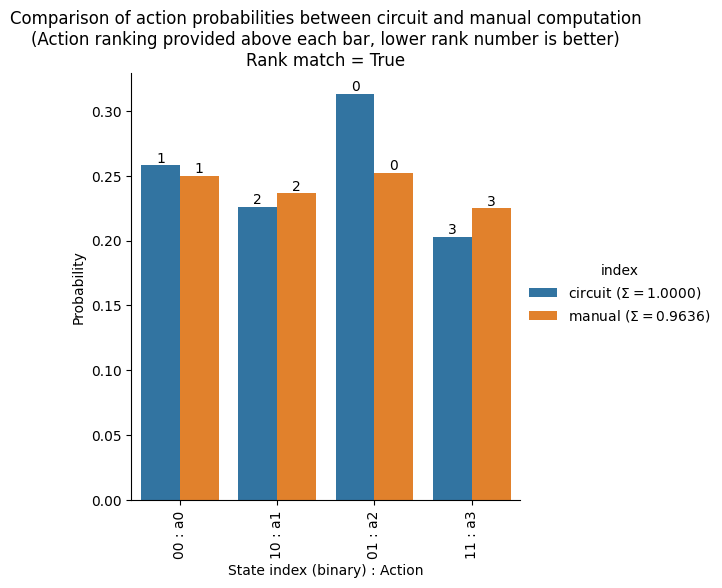

In [30]:
### To make visual comparison easier, plot action probabilities from quantum circuit and manual computation together on same chart.

df = pd.DataFrame(np.array([probs_actions, returns_probs_matrix @ returns_atoms_values_original]), columns=[f"a{i}" for i in range(n_actions)], index=[f"circuit ($\\Sigma = {probs_actions.sum():.4f}$)", f"manual ($\\Sigma = {(returns_probs_matrix @ returns_atoms_values_original).sum():.4f}$)"])
df = df.reset_index()
df = df.melt(id_vars='index')

plt.figure()
g = sns.catplot(data=df, x='variable', y='value', hue='index', kind="bar", legend=True)
ax = g.facet_axis(0, 0)
for idx, (container, actionrank) in enumerate(zip(ax.containers, [action_rank_circuit_probs, action_rank_manual_compute])):
    # labels = [f"{v.get_height():.4f}" for v in container]
    actionrank = sorted(actionrank, key=lambda ar: ar.action)
    labels = [f"{actionrank[j].rank}" for j, v in enumerate(container)]
    ax.bar_label(container, labels=labels, label_type='edge')
g.set_xticklabels([f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
g.set_xlabels("State index (binary) : Action")
g.set_ylabels("Probability")
plt.title(f"Comparison of action probabilities between circuit and manual computation\n(Action ranking provided above each bar, lower rank number is better)\nRank match = {action_rank_manual_compute == action_rank_circuit_probs}")

Text(0.5, 0, 'State index (binary) : Return atom')

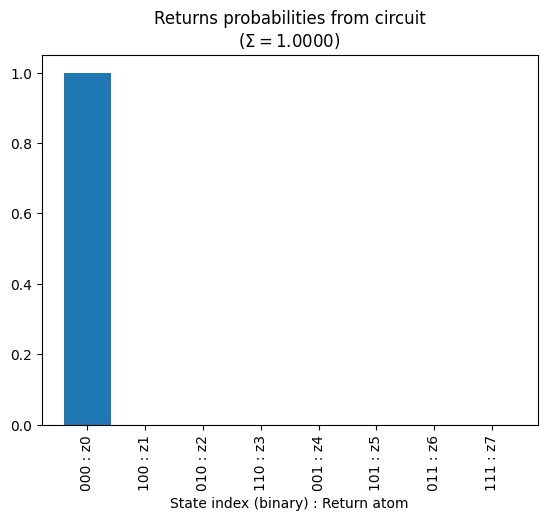

In [31]:
### Probabilities derived from measuring the returns qubits in the circuit.

plt.bar(np.arange(n_returns), probs_returns)
plt.xticks(np.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Returns probabilities from circuit\n($\\Sigma = {probs_returns.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")